<a href="https://colab.research.google.com/github/bcramp/ML/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

HW 4

Title: Heart Disease Classification using Decision Trees & Support Vector Machines

Name: Brennen Cramp

Date: 10/17/2026

---

# Task 1: Load the dataset into a Pandas DataFrame

The following code cell pip-installs and imports the Cleveland Heart Disease dataset from the UCI Machine Learning Repository (ucimlrepo) package. This data is then loaded into a Pandas DataFrame.

In [25]:
# Install the UCI ML Repository library
# Import Pandas for handling tabular data
# Import NumPy for handling scientific computing and math operations
!pip install ucimlrepo
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# Grab the Heart Disease dataset from the UCI Repository, its ID=45
heart_disease = fetch_ucirepo(id=45)

# Extract features/targets as DataFrames
features = heart_disease.data.features
targets = heart_disease.data.targets

# Task 1: Combine features and targets into one DataFrame
df = pd.concat([features, targets], axis=1)

# Task 2: Inspect and analyze features

The following code cells ***[multiple (2 total) code cells]*** are using structural inspection methods (head(), info(), describe()) to analyze continuous and categorical features.

In [26]:
# Task 2: Use structural inspection methods (head(), info(), describe()) to analyze continuous and categorical features.
print("--- Task 2: Inspection ---")
print("\nFirst 5 rows of the dataset:")
df.head()

--- Task 2: Inspection ---

First 5 rows of the dataset:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [27]:
print("General information about the Cleveland Heart Disease dataset:\n")
df.info()

print("\nSummary statistics of numerical columns:\n")
df.describe()

General information about the Cleveland Heart Disease dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Summary statistics of numerical columns:



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


# Task 3: Quantify missing/implicit values and implement a structured imputation strategy

The following code cell quantifies and handles any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings). I also convert and drop the 'num' target variable into a new binary indicator field 'target' (0 = healthy; 1+ = disease present) in the enitre dataframe. The code cell also implements a structured imputation strategy using Scikit-Learn's SimpleImputer. This will NOT use .fit_transform() or .fit() to avoid data leakage.

In [28]:
# Import Scikit-Learn's SimpleImputer to handle missing entries
from sklearn.impute import SimpleImputer

# ----------------------------- 1st Step -----------------------------
# Task 3.1: Quantify any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings).
print("--- Task 3.1: Quantify any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) ---")

# Quantify missing values per column
print("\n--- Missing Value Counts ---")
print(df.isnull().sum())

# Do a double check and display count of missing values
print("\nExplicit NaNs found within the features dataframe:")
print(features.isna().sum()[features.isna().sum() > 0])

# Converts and drops the 'num' target into a binary indicator field ('target') where:
# 0 stays 0 (healthy), values 1+ become 1 (heart disease is present)
df['target'] = (df['num'] >= 1).astype(int)
df = df.drop(columns=['num'])

# Replace implicit '?' placeholders with NumPy NaNs
# IMPORTANT: This will not do anything since the datatypes are all int/float already. I only added this due to
# the assignment's direction for this task: "(checking for non-standard placeholders such as ? strings)"
features = features.replace('?', np.nan)
print("\nTotal NaNs present after identifying hidden '?' strings:")
print(features.isna().sum()[features.isna().sum() > 0])

# Quantify the missing values per column, again
# This also helps to ensure that I dropped 'num' and now have my new 'target' field in the whole dataframe
print("\n--- New Missing Value Counts ---")
print(df.isnull().sum())

# ----------------------------- 2nd Step -----------------------------
# Task 3.2: Implement/define a structured imputation strategy using Scikit-Learn's SimpleImputer.
print("\n--- Task 3.2: Implement/define a structured imputation strategy using Scikit-Learn's SimpleImputer ---")

# --- IMPORTANT NOTE: ---
# I will NOT use .fit_transform() during this step, on the training data, to avoid data leaks from my
# testing data into my training phase.

# Identify numeric and categorical columns/features in the dataframe
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

# Next, I want to define the numeric columns using the median (instead of mean due to extreme outliers possibly skewing the mean)
print("Defining the imputer for the numeric columns using the median values per column.")
num_imputer = SimpleImputer(missing_values=np.nan, strategy='median')

# Additionally, I want to define the imputer for the categorical columns using the most occurring value
print("Defining the imputer for the categorical columns using the most occurring value per column.")
cat_imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

print("Imputation strategies successfully defined!")

--- Task 3.1: Quantify any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) ---

--- Missing Value Counts ---
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Explicit NaNs found within the features dataframe:
ca      4
thal    2
dtype: int64

Total NaNs present after identifying hidden '?' strings:
ca      4
thal    2
dtype: int64

--- New Missing Value Counts ---
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

--- Task 3.2: Implement/define a structured imputation strategy using Scikit-Learn's SimpleImputer ---
Defining the imputer for the numeric columns using the median values per column.
Defining the 

# Task 4: Isolate numerical/categorical features and apply scaling (numeric) and encoding (categoric) to columns

The following code cell isolates numerical and categorical features, then builds a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler AND MinMaxScaler - each has thier own pipeline) to numerical columns and encoding (OneHotEncoder) to categorical columns. This section will also include splitting the data as to avoid any possibilities of data leakage!

In [29]:
# Task 4: Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies
# appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and encoding (OneHotEncoder) to categorical columns.

# Import needed functionalities from Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

print("--- Task 4: Isolate features and build preprocessing pipelines ---")

# Create X (features) and y (new binary target)
X = df.drop(columns=['target'])
y = df['target']

# Splits the data using an 80/20 split (20% for test) and I will also set the random seed to be 100.
# I set stratify along the target to keep balance of heart disease vs healthy patients identical in both of my sets.
test_ratio = 0.2
seed = 100
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_ratio, random_state=seed, stratify=y
)

# Create individual pipeline for the numeric features using my median imputer from Task 3.2 and StandardScaler
num_transformer_standard = Pipeline(steps=[
    ('imputer', num_imputer),
    ('scaler', StandardScaler())
])

# Create individual pipeline for the numeric features using my median imputer from Task 3.2 and MinMaxScaler
num_transformer_min_max = Pipeline(steps=[
    ('imputer', num_imputer),
    ('scaler', MinMaxScaler())
])

# Create individual pipeline for the categorical features using my most fequent imputer from Task 3.2
cat_transformer = Pipeline(steps=[
    ('imputer', cat_imputer),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Make the preprocessor with the StandardScaler for numerical features by combining the pipelines into a single ColumnTransformer
preprocessor_standard = ColumnTransformer(
    transformers=[
        ('num', num_transformer_standard, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Make the preprocessor with the MinMaxScalar for numerical features by combining the pipelines into a single ColumnTransformer
preprocessor_min_max = ColumnTransformer(
    transformers=[
        ('num', num_transformer_min_max, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

print("\nSuccessfully built both StandardScaler and MinMaxScaler preprocessor pipelines!")

--- Task 4: Isolate features and build preprocessing pipelines ---

Successfully built both StandardScaler and MinMaxScaler preprocessor pipelines!


# Task 5: Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.

The following code cells ***[multiple (2 total) code cells]*** instantiates and trains a pipeline by appending a Support Vector Classifier (SVC) onto both the StandardScaler and MinMaxScaler preprocessors. Each preprocessor will also fit the pipeline on X_train and y_train, make predictions on X_test, and will print the evaluations (Confusion Matrix, a Classification Report, and ROC-AUC Score).

--- Task 5.1: Support Vector Classifier Training & Evaluation using StandardScaler ---

-------------------- Start of using StandardScaler --------------------

----- SVC Model Evaluation Metrics using StandardScaler -----

-- Confusion Matrix using StandardScaler: --
[[27  6]
 [ 8 20]]

-------------------------------------------

-- Classification Report using StandardScaler: --
              precision    recall  f1-score   support

           0       0.77      0.82      0.79        33
           1       0.77      0.71      0.74        28

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61


-------------------------------------------
ROC-AUC Score using the StandardScaler for numerical features: 0.8723

-------------------- End of using StandardScaler --------------------


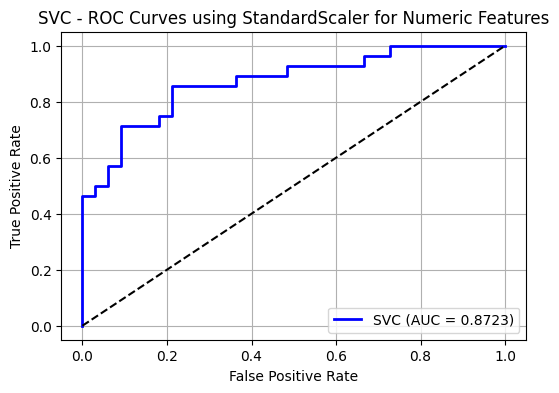

In [35]:
# Task 5: Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within
# your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.

# Import needed functionalities from Scikit-Learn
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

print("--- Task 5.1: Support Vector Classifier Training & Evaluation using StandardScaler ---")

# Instantiates the SVC model with configs
svc_model = SVC(
    kernel='rbf', probability=True, random_state=seed
)

# Builds final pipeline using the StandardScaler preprocessor
svc_pipeline_ss = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    ('classifier', svc_model)
])

# Train the model
# IMPORTANT: Fit the pipeline ONLY on the training data to prevent data leakage!!
svc_pipeline_ss.fit(X_train, y_train)

# Generates predictions test set and extract probabilities for the positive target (1)
y_pred_svc_ss = svc_pipeline_ss.predict(X_test)
y_prob_svc_ss = svc_pipeline_ss.predict_proba(X_test)[:, 1]

# Computes and prints eval metrics (confusion and classification)
print(f"\n-------------------- Start of using StandardScaler --------------------")
print("\n----- SVC Model Evaluation Metrics using StandardScaler -----")
print("\n-- Confusion Matrix using StandardScaler: --")
print(confusion_matrix(y_test, y_pred_svc_ss))
print("\n-------------------------------------------")

print("\n-- Classification Report using StandardScaler: --")
print(classification_report(y_test, y_pred_svc_ss))
print("\n-------------------------------------------")

# Calcs the ROC_AUC score
svc_auc_ss = roc_auc_score(y_test, y_prob_svc_ss)
print(f"ROC-AUC Score using the StandardScaler for numerical features: {svc_auc_ss:.4f}")
print(f"\n-------------------- End of using StandardScaler --------------------")

# Calcs and plots the ROC curve data
# I do not care about the 3rd returned value so it will be 'ignored'
false_pos_rate_ss, true_pos_rate_ss, ignored = roc_curve(y_test, y_prob_svc_ss)

# Styling for the ROC plot
plt.figure(figsize=(6, 4))
plt.plot(false_pos_rate_ss, true_pos_rate_ss, label=f"SVC (AUC = {svc_auc_ss:.4f})", color='blue', lw=2)
plt.plot([0, 1], [0, 1], color='black', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('SVC - ROC Curves using StandardScaler for Numeric Features')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

--- Task 5.2: Support Vector Classifier Training & Evaluation using MinMaxScaler ---

-------------------- Start of using MinMaxScaler --------------------

----- SVC Model Evaluation Metrics using MinMaxScaler -----

-- Confusion Matrix using MinMaxScaler: --
[[25  8]
 [ 9 19]]

-------------------------------------------

-- Classification Report using MinMaxScaler: --
              precision    recall  f1-score   support

           0       0.74      0.76      0.75        33
           1       0.70      0.68      0.69        28

    accuracy                           0.72        61
   macro avg       0.72      0.72      0.72        61
weighted avg       0.72      0.72      0.72        61


-------------------------------------------
ROC-AUC Score using the MinMaxScaler for numerical features: 0.8528

-------------------- End of using MinMaxScaler --------------------


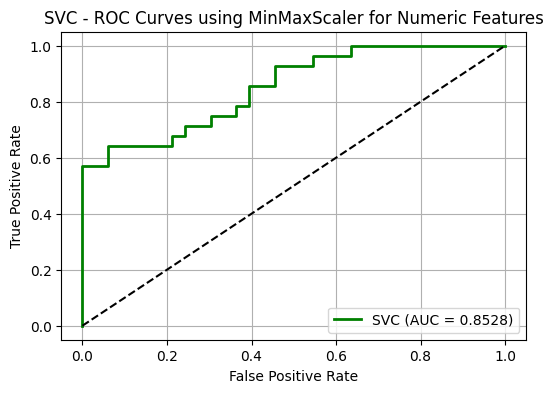

In [36]:
# Task 5: Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within
# your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.

print("--- Task 5.2: Support Vector Classifier Training & Evaluation using MinMaxScaler ---")

# Instantiates the SVC model with configs
svc_model = SVC(
    kernel='rbf', probability=True, random_state=seed
)

# Builds final pipeline using the MinMaxScaler preprocessor
svc_pipeline_mm = Pipeline(steps=[
    ('preprocessor', preprocessor_min_max),
    ('classifier', svc_model)
])

# Train the model
# IMPORTANT: Fit the pipeline ONLY on the training data to prevent data leakage!!
svc_pipeline_mm.fit(X_train, y_train)

# Generates predictions on test set and extract probabilities for the positive target (1)
y_pred_svc_mm = svc_pipeline_mm.predict(X_test)
y_prob_svc_mm = svc_pipeline_mm.predict_proba(X_test)[:, 1]

# Computes and prints eval metrics (confusion and classification)
print(f"\n-------------------- Start of using MinMaxScaler --------------------")
print("\n----- SVC Model Evaluation Metrics using MinMaxScaler -----")
print("\n-- Confusion Matrix using MinMaxScaler: --")
print(confusion_matrix(y_test, y_pred_svc_mm))
print("\n-------------------------------------------")

print("\n-- Classification Report using MinMaxScaler: --")
print(classification_report(y_test, y_pred_svc_mm))
print("\n-------------------------------------------")

# Calcs the ROC_AUC score
svc_auc_mm = roc_auc_score(y_test, y_prob_svc_mm)
print(f"ROC-AUC Score using the MinMaxScaler for numerical features: {svc_auc_mm:.4f}")
print(f"\n-------------------- End of using MinMaxScaler --------------------")

# Calcs and plots the ROC curve data
# I do not care about the 3rd returned value so it will be 'ignored'
false_pos_rate_mm, true_pos_rate_mm, ignored = roc_curve(y_test, y_prob_svc_mm)

# Styling for the ROC plot
plt.figure(figsize=(6, 4))
plt.plot(false_pos_rate_mm, true_pos_rate_mm, label=f"SVC (AUC = {svc_auc_mm:.4f})", color='green', lw=2)
plt.plot([0, 1], [0, 1], color='black', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('SVC - ROC Curves using MinMaxScaler for Numeric Features')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Task 6: Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate its performance using identical metrics to compare against your SVC model.

The following code cells ***[multiple (2 total) code cells]*** instantiates and trains a pipeline by adding a Decision Tree Classifier (DTC) onto both the StandardScaler and MinMaxScaler preprocessors. Each preprocessor will also fit the pipeline on X_train and y_train, make predictions on X_test, and will print the evaluations (Confusion Matrix, a Classification Report, and ROC-AUC Score).

--- Task 6.1: Decision Tree Classifier Training & Evaluation using StandardScaler ---

-------------------- Start of using StandardScaler --------------------

----- Decision Tree Model Evaluation Metrics using StandardScaler -----

-- Confusion Matrix using StandardScaler:: --
[[27  6]
 [ 9 19]]

-------------------------------------------

-- Classification Report using StandardScaler: --
              precision    recall  f1-score   support

           0       0.75      0.82      0.78        33
           1       0.76      0.68      0.72        28

    accuracy                           0.75        61
   macro avg       0.76      0.75      0.75        61
weighted avg       0.75      0.75      0.75        61


-------------------------------------------
ROC-AUC Score using the StandardScaler for numerical features: 0.7484

-------------------- End of using StandardScaler --------------------


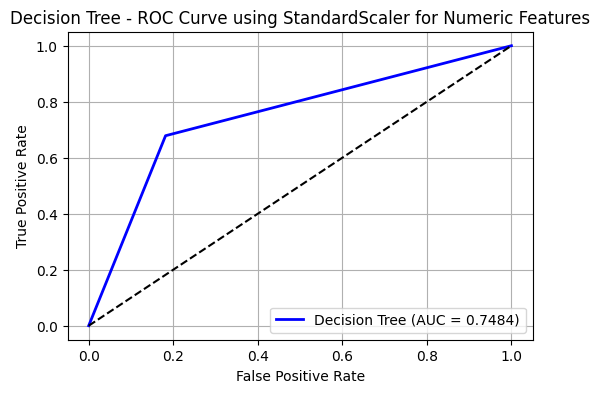

In [39]:
# Task 6: Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate
# its performance using identical metrics to compare against your SVC model.

# Import needed DTC from Scikit-Learn
from sklearn.tree import DecisionTreeClassifier

print("--- Task 6.1: Decision Tree Classifier Training & Evaluation using StandardScaler ---")

# Instantiates the DTC model and sets the random_state to match the seed user earlier
dt_model = DecisionTreeClassifier(random_state=seed)

# Builds final pipeline using the StandardScaler preprocessor
dt_pipeline_ss = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    ('classifier', dt_model)
])

# Train the model
# IMPORTANT: Fit the pipeline ONLY on the training data to prevent data leakage!!
dt_pipeline_ss.fit(X_train, y_train)

# Generates predictions on test set and extract probabilities for the positive target (1)
y_pred_dt_ss = dt_pipeline_ss.predict(X_test)
y_prob_dt_ss = dt_pipeline_ss.predict_proba(X_test)[:, 1]

# Computes and prints eval metrics (confusion and classification)
print(f"\n-------------------- Start of using StandardScaler --------------------")
print("\n----- Decision Tree Model Evaluation Metrics using StandardScaler -----")
print("\n-- Confusion Matrix using StandardScaler:: --")
print(confusion_matrix(y_test, y_pred_dt_ss))
print("\n-------------------------------------------")

print("\n-- Classification Report using StandardScaler: --")
print(classification_report(y_test, y_pred_dt_ss))
print("\n-------------------------------------------")

# Calcs the ROC_AUC score
dt_auc_ss = roc_auc_score(y_test, y_prob_dt_ss)
print(f"ROC-AUC Score using the StandardScaler for numerical features: {dt_auc_ss:.4f}")
print(f"\n-------------------- End of using StandardScaler --------------------")

# Calcs and plots the ROC curve data
# I do not care about the 3rd returned value so it will be 'ignored'
false_pos_rate_dt_ss, true_pos_rate_dt_ss, ignored = roc_curve(y_test, y_prob_dt_ss)

# Styling for the ROC plot
plt.figure(figsize=(6, 4))
plt.plot(false_pos_rate_dt_ss, true_pos_rate_dt_ss, label=f"Decision Tree (AUC = {dt_auc_ss:.4f})", color='blue', lw=2)
plt.plot([0, 1], [0, 1], color='black', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Decision Tree - ROC Curve using StandardScaler for Numeric Features')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

--- Task 6.2: Decision Tree Classifier Training & Evaluation using MinMaxScaler ---

-------------------- Start of using MinMaxScaler --------------------

----- Decision Tree Model Evaluation Metrics using MinMaxScaler -----

-- Confusion Matrix using MinMaxScaler: --
[[27  6]
 [ 9 19]]

-------------------------------------------

-- Classification Report using MinMaxScaler: --
              precision    recall  f1-score   support

           0       0.75      0.82      0.78        33
           1       0.76      0.68      0.72        28

    accuracy                           0.75        61
   macro avg       0.76      0.75      0.75        61
weighted avg       0.75      0.75      0.75        61


-------------------------------------------
ROC-AUC Score using the MinMaxScaler for numerical features: 0.7484

-------------------- End of using MinMaxScaler --------------------


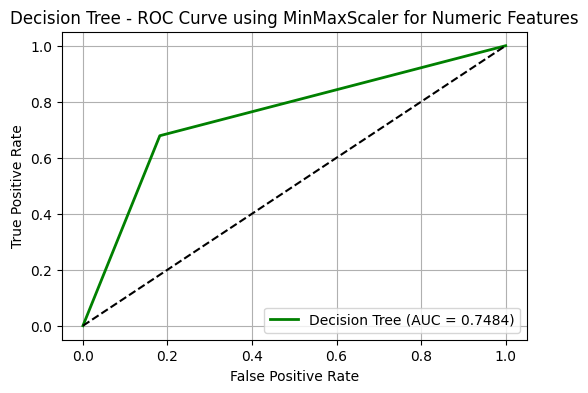

In [40]:
# Task 6: Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate
# its performance using identical metrics to compare against your SVC model.

print("--- Task 6.2: Decision Tree Classifier Training & Evaluation using MinMaxScaler ---")

# Instantiates the DTC model and sets the random_state to match the seed user earlier
dt_model = DecisionTreeClassifier(random_state=seed)

# Builds final pipeline using the MinMaxScaler preprocessor
dt_pipeline_mm = Pipeline(steps=[
    ('preprocessor', preprocessor_min_max),
    ('classifier', dt_model)
])

# Train the model
# IMPORTANT: Fit the pipeline ONLY on the training data to prevent data leakage!!
dt_pipeline_mm.fit(X_train, y_train)

# Generates predictions on test set and extract probabilities for the positive target (1)
y_pred_dt_mm = dt_pipeline_mm.predict(X_test)
y_prob_dt_mm = dt_pipeline_mm.predict_proba(X_test)[:, 1]

# Computes and prints eval metrics (confusion and classification)
print(f"\n-------------------- Start of using MinMaxScaler --------------------")
print("\n----- Decision Tree Model Evaluation Metrics using MinMaxScaler -----")
print("\n-- Confusion Matrix using MinMaxScaler: --")
print(confusion_matrix(y_test, y_pred_dt_mm))
print("\n-------------------------------------------")

print("\n-- Classification Report using MinMaxScaler: --")
print(classification_report(y_test, y_pred_dt_mm))
print("\n-------------------------------------------")

# Calcs the ROC_AUC score
dt_auc_mm = roc_auc_score(y_test, y_prob_dt_mm)
print(f"ROC-AUC Score using the MinMaxScaler for numerical features: {dt_auc_mm:.4f}")
print(f"\n-------------------- End of using MinMaxScaler --------------------")

# Calcs and plots the ROC curve data
# I do not care about the 3rd returned value so it will be 'ignored'
false_pos_rate_dt_mm, true_pos_rate_dt_mm, ignored = roc_curve(y_test, y_prob_dt_mm)

# Styling for the ROC plot
plt.figure(figsize=(6, 4))
plt.plot(false_pos_rate_dt_mm, true_pos_rate_dt_mm, label=f"Decision Tree (AUC = {dt_auc_mm:.4f})", color='green', lw=2)
plt.plot([0, 1], [0, 1], color='black', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Decision Tree - ROC Curve using MinMaxScaler for Numeric Features')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Task 7: Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such as C and gamma) to optimize cross-validation performance.

The following code cells ***[multiple (2 total) code cells]*** sets up a parameter grid to track the C and gamma with the "classifier__" prefix so the GridSearchCV will know which step of the pipeline to apply them to. Then using
5-fold cross-validation strategy, I will optimize for the ROC-AUC Score for both SVC pipelines (7.1 - StandardScaler; 7.2 - MinMaxScaler) to maximize area under the curve, printing the evaluation metrics for each SVC pipeline.

In [41]:
# Task 7: Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such
# as C and gamma) to optimize cross-validation performance.

# Import needed functionality from Scikit-Learn
from sklearn.model_selection import GridSearchCV

print("--- Task 7.1: Hyperparameter Tuning for SVC via GridSearchCV using StandardScaler ---")

# Creates grid of params to search over (I used the 'classifier__' prefix to route params into the pipeline step)
param_grid = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
}

# Recreate the base SVC pipeline using StandardScaler
base_svc_pipeline_ss = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    ('classifier', SVC(kernel='rbf', probability=True, random_state=seed))
])

# Create the Grid Search object and use 5-fold cross-validation. Here, I want to optimize for ROC-AUC score.
# IMPORTANT: This was taking some time so I found the n_jobs param and set it to use all my CPU cores
grid_search = GridSearchCV(
    estimator=base_svc_pipeline_ss,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    verbose=1,
    n_jobs=-1
)

# Executes the grid search on the training data
print("--- Starting grid search for SVC pipeline using StandardScaler ---")
grid_search.fit(X_train, y_train)
print("--- Ending grid search ---")

# Print the optimal param combos
print("\n--- Hyperparameter Optimization Results using StandardScaler ---")
print(f"Best ROC-AUC Score (StandardScaler) from Cross-Validation: {grid_search.best_score_:.4f}")
print("Best Parameter Settings Found for SVC using StandardScaler:")
for param, val in grid_search.best_params_.items():
    print(f" - {param.split('__')[1]}: {val}")
print("\n-------------------------------------------")

# Evaluate the optimized model on the unseen test split
best_model_ss = grid_search.best_estimator_
y_pred_opt_ss = best_model_ss.predict(X_test)
y_prob_opt_ss = best_model_ss.predict_proba(X_test)[:, 1]

print("\n--- Optimized SVC Test Set Evaluation ---")
print("\n-- Confusion Matrix for SVC using StandardScaler: --")
print(confusion_matrix(y_test, y_pred_opt_ss))
print("\n-------------------------------------------")

print("\n-- Classification Report for SVC using StandardScaler: --")
print(classification_report(y_test, y_pred_opt_ss))
print("\n-------------------------------------------")

opt_auc_ss = roc_auc_score(y_test, y_prob_opt_ss)
print(f"\nOptimized SVC (StandardScaler) Test ROC-AUC Score: {opt_auc_ss:.4f}")

--- Task 7.1: Hyperparameter Tuning for SVC via GridSearchCV using StandardScaler ---
--- Starting grid search for SVC pipeline using Standard Scaler ---
Fitting 5 folds for each of 24 candidates, totalling 120 fits
--- Ending grid search ---

--- Hyperparameter Optimization Results using StandardScaler ---
Best ROC-AUC Score (StandardScaler) from Cross-Validation: 0.9215
Best Parameter Settings Found for SVC using StandardScaler:
  C: 1
  gamma: 0.01

-------------------------------------------

--- Optimized SVC Test Set Evaluation ---

-- Confusion Matrix for SVC using StandardScaler: --
[[27  6]
 [ 7 21]]

-------------------------------------------

-- Classification Report for SVC using StandardScaler: --
              precision    recall  f1-score   support

           0       0.79      0.82      0.81        33
           1       0.78      0.75      0.76        28

    accuracy                           0.79        61
   macro avg       0.79      0.78      0.78        61
weighte

In [42]:
# Task 7: Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such
# as C and gamma) to optimize cross-validation performance.

print("--- Task 7.2: Hyperparameter Tuning for SVC via GridSearchCV using MinMaxScaler ---")

# Recreates grid of params to search over (I used the 'classifier__' prefix to route params into the pipeline step)
param_grid = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
}

# Recreate the base SVC pipeline using MinMaxScaler
base_svc_pipeline_mm = Pipeline(steps=[
    ('preprocessor', preprocessor_min_max),
    ('classifier', SVC(kernel='rbf', probability=True, random_state=seed))
])

# Create the Grid Search object and use 5-fold cross-validation. Here, I want to optimize for ROC-AUC score.
# IMPORTANT: This was taking some time so I found the n_jobs param and set it to use all my CPU cores
grid_search = GridSearchCV(
    estimator=base_svc_pipeline_mm,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    verbose=1,
    n_jobs=-1
)

# Executes the grid search on the training data
print("--- Starting grid search for SVC pipeline using MinMaxScaler ---")
grid_search.fit(X_train, y_train)
print("--- Ending grid search ---")

# Print the optimal param combos
print("\n--- Hyperparameter Optimization Results using MinMaxScaler ---")
print(f"Best ROC-AUC Score (MinMaxScaler) from Cross-Validation: {grid_search.best_score_:.4f}")
print("Best Parameter Settings Found for SVC using MinMaxScaler:")
for param, val in grid_search.best_params_.items():
    print(f" - {param.split('__')[1]}: {val}")
print("\n-------------------------------------------")

# Evaluate the optimized model on the unseen test split
best_model_mm = grid_search.best_estimator_
y_pred_opt_mm = best_model_mm.predict(X_test)
y_prob_opt_mm = best_model_mm.predict_proba(X_test)[:, 1]

print("\n--- Optimized SVC Test Set Evaluation ---")
print("\n-- Confusion Matrix for SVC using MinMaxScaler: --")
print(confusion_matrix(y_test, y_pred_opt_mm))
print("\n-------------------------------------------")

print("\n-- Classification Report for SVC using MinMaxScaler: --")
print(classification_report(y_test, y_pred_opt_mm))
print("\n-------------------------------------------")

opt_auc_mm = roc_auc_score(y_test, y_prob_opt_mm)
print(f"\nOptimized SVC (MinMaxScaler) Test ROC-AUC Score: {opt_auc_mm:.4f}")

--- Task 7.2: Hyperparameter Tuning for SVC via GridSearchCV using MinMaxScaler ---
--- Starting grid search for SVC pipeline using MinMaxScaler ---
Fitting 5 folds for each of 24 candidates, totalling 120 fits
--- Ending grid search ---

--- Hyperparameter Optimization Results using MinMaxScaler ---
Best ROC-AUC Score (MinMaxScaler) from Cross-Validation: 0.9236
Best Parameter Settings Found for SVC using MinMaxScaler:
 - C: 0.1
 - gamma: auto

-------------------------------------------

--- Optimized SVC Test Set Evaluation ---

-- Confusion Matrix for SVC using MinMaxScaler: --
[[28  5]
 [ 9 19]]

-------------------------------------------

-- Classification Report for SVC using MinMaxScaler: --
              precision    recall  f1-score   support

           0       0.76      0.85      0.80        33
           1       0.79      0.68      0.73        28

    accuracy                           0.77        61
   macro avg       0.77      0.76      0.77        61
weighted avg      

# Task 8: Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how the model separates patients with heart disease from healthy patients.

The following code cells ***[multiple (2 total) code cells]*** both a decision tree (using Scikit-Learn's plot_tree) AND feature importances were created for both StandardScaler and MinMaxScaler pipelines from the Decision Tree section of the assignment (Task 6).

--- Task 8.1: Decision Tree Interpretation & Feature Importances (StandardScaler) ---


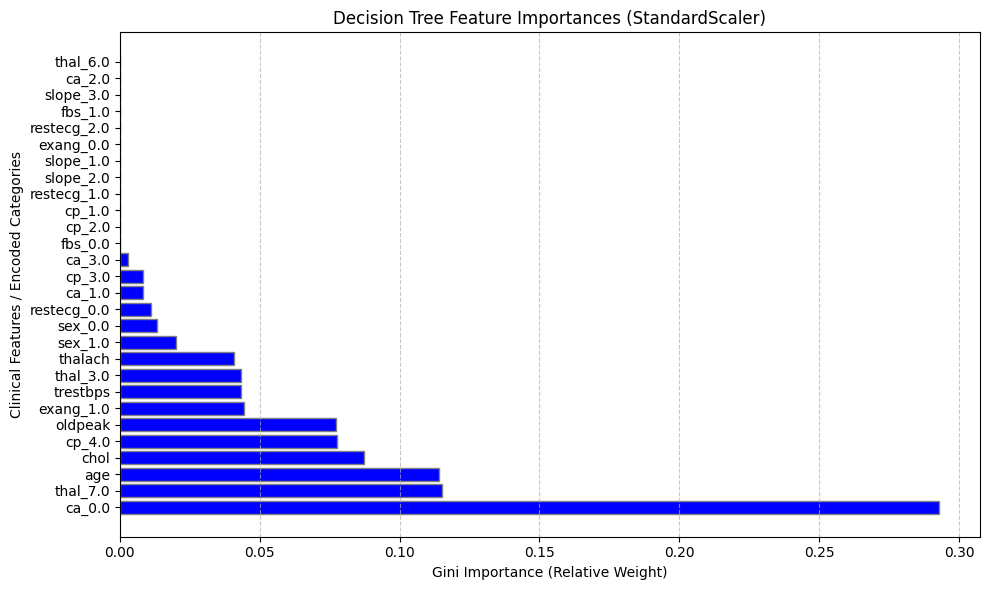

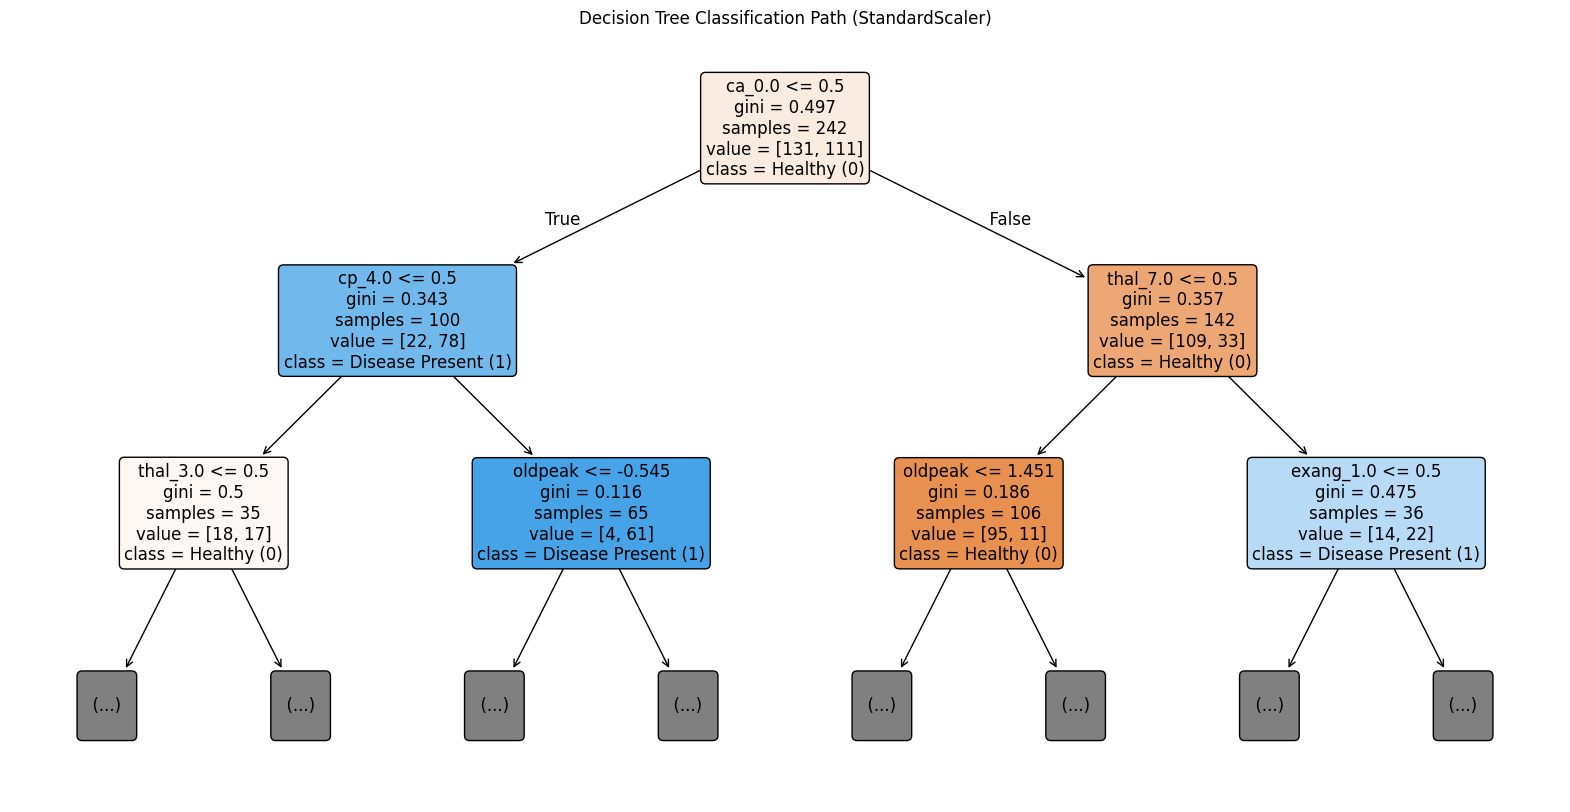

In [43]:
# Task 8: Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how
# the model separates patients with heart disease from healthy patients.

# Imports plot_tree from Scikit-Learn to plot the decision tree
from sklearn.tree import plot_tree

print("--- Task 8.1: Decision Tree Interpretation & Feature Importances (StandardScaler) ---")

# Use the fitted transformer and classifier from the DT pipelines for StandardScaler
fitted_preprocessor_ss = dt_pipeline_ss.named_steps['preprocessor']
fitted_tree_model_ss = dt_pipeline_ss.named_steps['classifier']

# Get the dynamically generated features from the encoder pipeline
encoded_cat_features_ss = (
    fitted_preprocessor_ss
      .named_transformers_['cat']
      .named_steps['encoder']
      .get_feature_names_out(cat_cols)
)

# Combines num names and encoded cat names into a single list
all_feature_names_ss = list(num_cols) + list(encoded_cat_features_ss)

# Extract feature importances
importances_ss = fitted_tree_model_ss.feature_importances_

# Pair features with their importance and will also sort them by their value of importance (most important first)
importance_df_ss = pd.DataFrame({
    'Feature': all_feature_names_ss,
    'Importance': importances_ss
}).sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(importance_df_ss['Feature'], importance_df_ss['Importance'], color='blue', edgecolor='gray')
plt.xlabel('Gini Importance (Relative Weight)')
plt.ylabel('Clinical Features / Encoded Categories')
plt.title('Decision Tree Feature Importances (StandardScaler)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Generates the Structural Tree Diagram (plot_tree)
# IMPORTANT: I want to limit max_depth to 2 (just root and child nodes) so the chart is easier to read
plt.figure(figsize=(20, 10))
plot_tree(
    fitted_tree_model_ss,
    max_depth=2,
    feature_names=all_feature_names_ss,
    class_names=['Healthy (0)', 'Disease Present (1)'],
    filled=True,
    rounded=True,
    fontsize=12
)
plt.title('Decision Tree Classification Path (StandardScaler)')
plt.show()

--- Task 8.2: Decision Tree Interpretation & Feature Importances (MinMaxScaler) ---


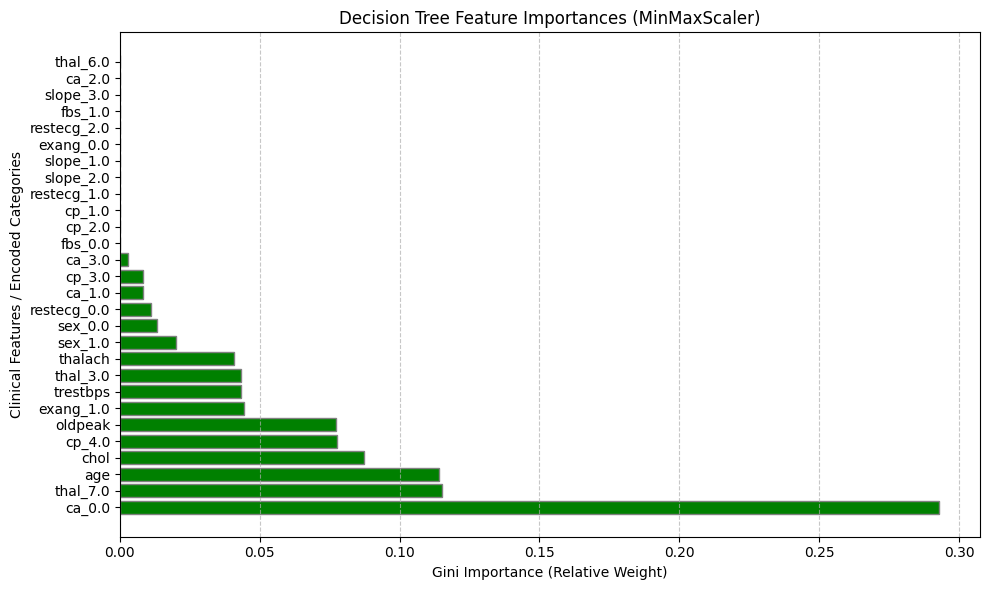

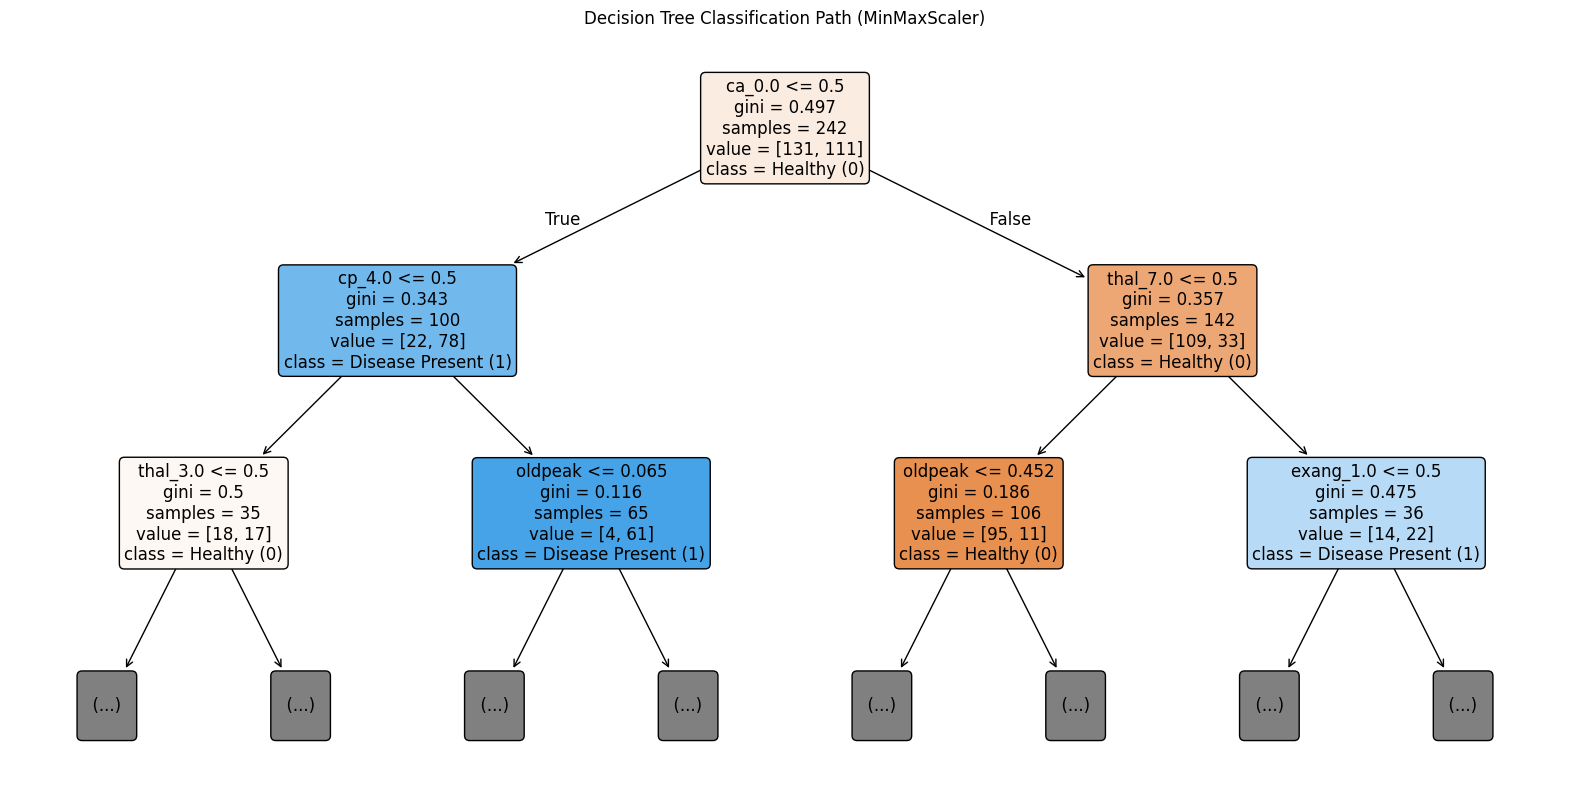

In [44]:
# Task 8: Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how
# the model separates patients with heart disease from healthy patients.

print("--- Task 8.2: Decision Tree Interpretation & Feature Importances (MinMaxScaler) ---")

# Use the fitted transformer and classifier from the Decision Tree pipelines for MinMaxScaler
fitted_preprocessor_mm = dt_pipeline_mm.named_steps['preprocessor']
fitted_tree_model_mm = dt_pipeline_mm.named_steps['classifier']

# Get the dynamically generated features from the encoder pipeline
encoded_cat_features_mm = (
    fitted_preprocessor_mm
      .named_transformers_['cat']
      .named_steps['encoder']
      .get_feature_names_out(cat_cols)
)

# Combines num names and encoded cat names into a single list
all_feature_names_mm = list(num_cols) + list(encoded_cat_features_mm)

# Extract feature importances
importances_mm = fitted_tree_model_mm.feature_importances_

# Pair features with their importance and will also sort them by their value of importance (most important first)
importance_df_mm = pd.DataFrame({
    'Feature': all_feature_names_mm,
    'Importance': importances_mm
}).sort_values(by='Importance', ascending=False)

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(importance_df_mm['Feature'], importance_df_mm['Importance'], color='green', edgecolor='gray')
plt.xlabel('Gini Importance (Relative Weight)')
plt.ylabel('Clinical Features / Encoded Categories')
plt.title('Decision Tree Feature Importances (MinMaxScaler)')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Generates the Structural Tree Diagram (plot_tree)
# IMPORTANT: I want to limit max_depth to 2 (just root and child nodes) so the chart is easier to read
plt.figure(figsize=(20, 10))
plot_tree(
    fitted_tree_model_mm,
    max_depth=2,
    feature_names=all_feature_names_mm,
    class_names=['Healthy (0)', 'Disease Present (1)'],
    filled=True,
    rounded=True,
    fontsize=12
)
plt.title('Decision Tree Classification Path (MinMaxScaler)')
plt.show()